In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN, KMeans
from sklearn.preprocessing import StandardScaler

In [32]:
df = pd.read_csv('logistica_baja_california.csv')
df.head()

,Latitud,Longitud,Tipo_Solicitud
0,32.520796,-116.992084,Recoleccion
1,32.566198,-117.046102,Recoleccion
2,32.461507,-117.062417,Viaje_Pasajero
3,32.510667,-117.023516,Viaje_Pasajero
4,32.498468,-117.019210,Viaje_Pasajero


In [33]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[['Latitud', 'Longitud']])

print("forma de x_scaled:", X_scaled.shape)
print("primeras filas de x_scaled:\n", X_scaled[:5])



forma de x_scaled: (3100, 2)
primeras filas de x_scaled:
 [[ 0.88335238 -0.73514142]
 [ 1.00618974 -0.94540065]
 [ 0.72294016 -1.00890342]
 [ 0.85594675 -0.85748798]
 [ 0.82294302 -0.84072749]]


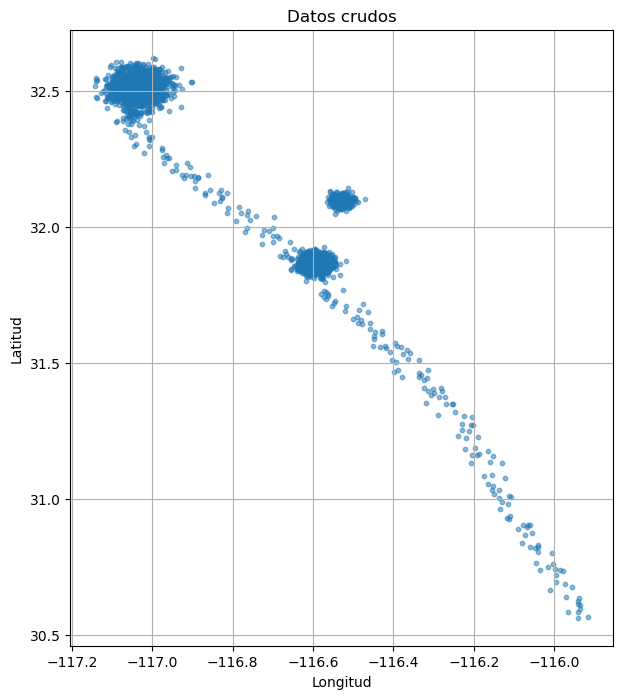

In [45]:
plt.figure(figsize=(7, 8))
plt.scatter(df['Longitud'], df['Latitud'], s=10, alpha=0.5)
plt.title('Datos crudos')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.grid(True)
plt.show()


In [43]:
kmeans = KMeans(n_clusters=3, random_state=42)
df['kmeans_cluster'] = kmeans.fit_predict(X_scaled)

centros_scaled = kmeans.cluster_centers_
centros_reales = scaler.inverse_transform(centros_scaled)

--- Coordenadas ---
cedes 1: Latitud = 32.506316, Longitud = -117.034964
cedes 2: Latitud = 31.040540, Longitud = -116.138027
cedes 3: Latitud = 31.912348, Longitud = -116.580728


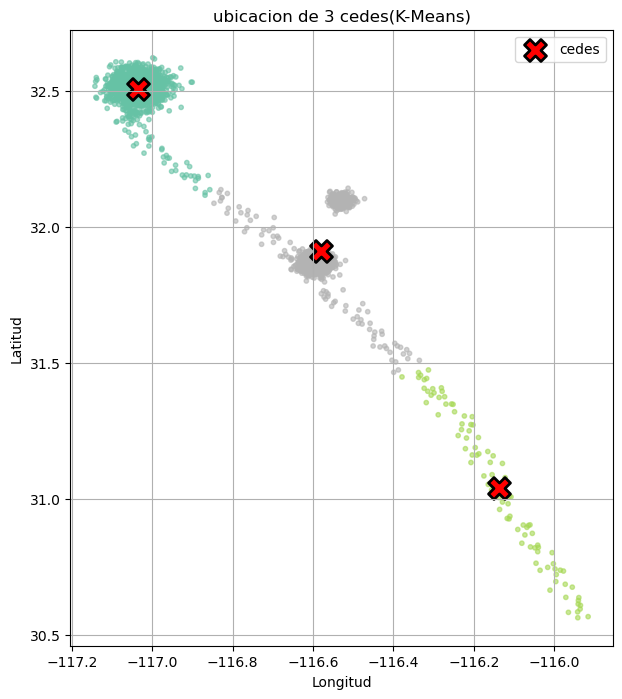

In [44]:
print("--- Coordenadas ---")
for i, (lat, lon) in enumerate(centros_reales, 1):
    print(f"cede {i}: Latitud = {lat:.6f}, Longitud = {lon:.6f}")

plt.figure(figsize=(7, 8))
plt.scatter(
    df['Longitud'],
    df['Latitud'],
    c=df['kmeans_cluster'],
    cmap='Set2',
    s=10,
    alpha=0.6,
)

plt.scatter(
    centros_reales[:, 1],
    centros_reales[:, 0],
    c='red',
    marker='X',
    s=250,
    linewidths=2,
    edgecolors='black',
    label='cedes',
)
plt.title('ubicacion de 3 cedes(K-Means)')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.legend()
plt.grid(True)
plt.show()


In [37]:
dbscan = DBSCAN(eps=0.15, min_samples=20)
df['dbscan_cluster'] = dbscan.fit_predict(X_scaled)

In [38]:
ruido = df[df['dbscan_cluster'] == -1]
ciudades = df[df['dbscan_cluster'] != -1]

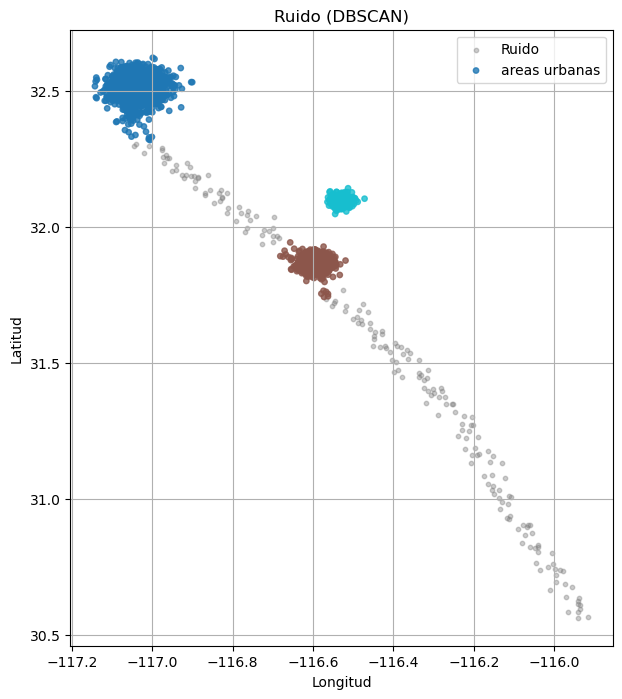

In [39]:
plt.figure(figsize=(7, 8))
plt.scatter(
    ruido['Longitud'],
    ruido['Latitud'],
    c='gray',
    s=10,
    alpha=0.4,
    label='Ruido',
)
plt.scatter(
    ciudades['Longitud'],
    ciudades['Latitud'],
    c=ciudades['dbscan_cluster'],
    cmap='tab10',
    s=15,
    alpha=0.8,
    label='areas urbanas',
)
plt.title('Ruido (DBSCAN)')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.legend()
plt.grid(True)
plt.show()

¿Dónde colocó el algoritmo que seleccionaron las Cedis?
Las colocó en Tijuana, Ensenada y San Quintin

¿Consideran que sus localizaciones hacen sentido?
La cede de San Quintin no lo se porque no llegan tantos pedidos a comparacion de las otras localizaciones. 

¿Por qué la matemática de este algoritmo provocó esto?
Kmeans utiliza distancias hacia el centroide y como hay puntos que tambien se encuentran por debajo en la grafica se vio comprometido a anadir un punto o centroide entre medio de la carretera de San Quintin.

¿Usaron el mismo algoritmo que en la misión anterior?
Se utilizo DBSCAN en vez de Kmeans.

¿De no ser así, porqué se comportaron diferentes?
Son diferentes porque Kmeans se encunetra obligado a categorizar en un grupo a todos los puntos y DBSCAN solo lso agrupa si estan lo suficientemente juntos.

¿A qué ciudades reales corresponden las 3 manchas urbanas que encontró su algoritmo?
Pertenecen a tijuana, ensenada y el valle creo que es.